In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

import warnings
warnings.filterwarnings('ignore')

Generate Synthetic Data

In [37]:
X, _, = make_moons(
    n_samples = 300,
    noise = 0.1,
    random_state = 42
)

Apply DBSCAN

In [42]:
dbscan = DBSCAN(
    eps = 0.2,
    min_samples = 4
)
labels = dbscan.fit_predict(X)

Plot the clusters

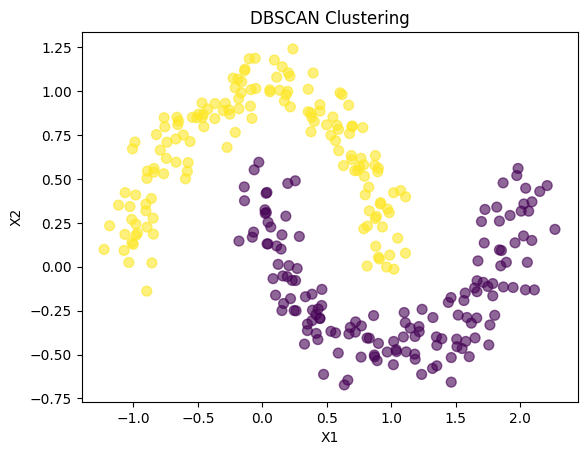

In [43]:
plt.scatter(X[:,0,], X[:,1], c = labels, cmap = 'viridis', s = 50, alpha = 0.6)
plt.title('DBSCAN Clustering')
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

**Choosing The Optimal Parameters ($\epsilon$ and MinPoints)**

Selecting the right $\epsilon$ and MinPoints is crucial for meaningfull clustering. Some techniques include:

1. **K-Distance Graph**
  * Sort the distance of each point to its `k-th` nearest neighbor
  * Plot these distance and find the `elbow point` where the rate of increase changes

In [33]:
from sklearn.neighbors import NearestNeighbors

min_samples = 4

neighbors = NearestNeighbors(n_neighbors = min_samples)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)

Sort The Distances and Grab The Distance to The K-th Neighbor

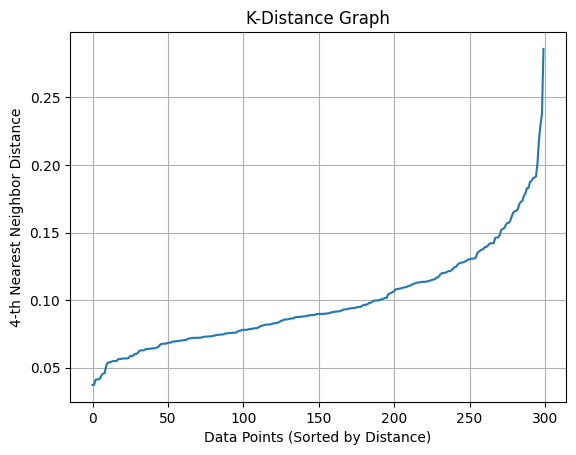

In [34]:
sorted_distances = np.sort(distances[:, -1])

plt.plot(sorted_distances)
plt.title("K-Distance Graph")
plt.xlabel("Data Points (Sorted by Distance)")
plt.ylabel(f"{min_samples}-th Nearest Neighbor Distance")
plt.grid(True)

plt.show()

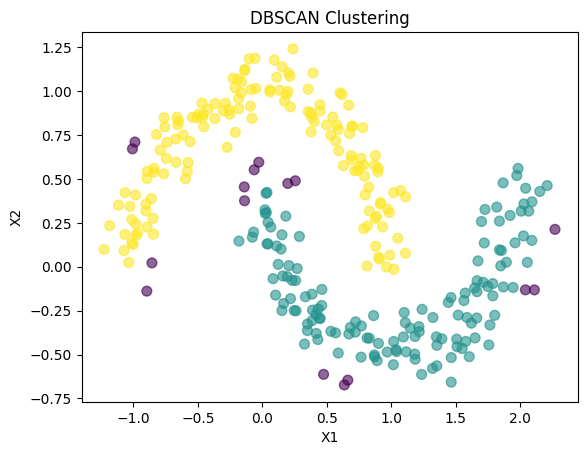

In [44]:
dbscan = DBSCAN(eps=0.15, min_samples=min_samples)
labels = dbscan.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=50, alpha=0.6)
plt.title('DBSCAN Clustering')
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

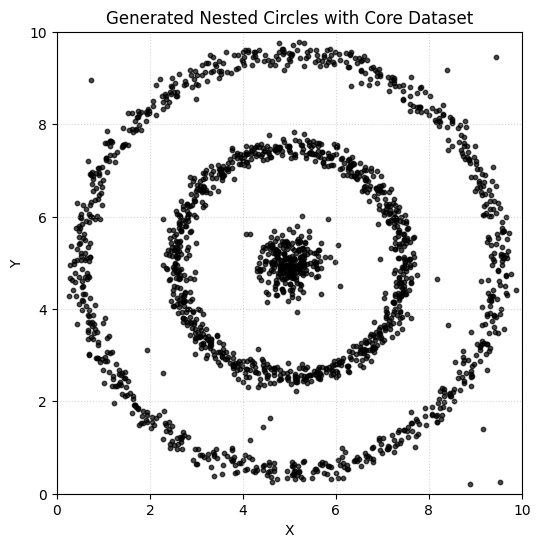

In [45]:
from sklearn.datasets import make_circles

# Set seed for reproducibility
np.random.seed(42)

# 1. Generate the two outer concentric rings
# We generate 1600 points total, split across two rings
X_rings, _ = make_circles(n_samples=1600, factor=0.55, noise=0.03)

# Scale and shift the rings so they sit between coordinates 0 and 10 (matching the image axes)
X_rings = (X_rings * 4.5) + 5.0

# 2. Generate the dense central core cluster
# Standard normal distribution centered at (5.0, 5.0)
n_core_samples = 250
core_noise = np.random.normal(loc=0.0, scale=0.35, size=(n_core_samples, 2))
X_core = core_noise + np.array([5.0, 5.0])

# 3. Generate the sparse background noise points (the black dots in the DBSCAN plot)
n_noise_samples = 30
X_noise = np.random.uniform(low=0.2, high=9.8, size=(n_noise_samples, 2))

# 4. Combine everything into one single dataset array
X = np.vstack([X_rings, X_core, X_noise])

# --- Plotting the generated dataset ---
plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], c='black', s=10, alpha=0.7)
plt.title("Generated Nested Circles with Core Dataset")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True, which='both', linestyle=':', alpha=0.5)
plt.xlim(0, 10)
plt.ylim(0, 10)
plt.show()


In [46]:
dbscan = DBSCAN(eps=0.15, min_samples= 4)
labels = dbscan.fit_predict(X)

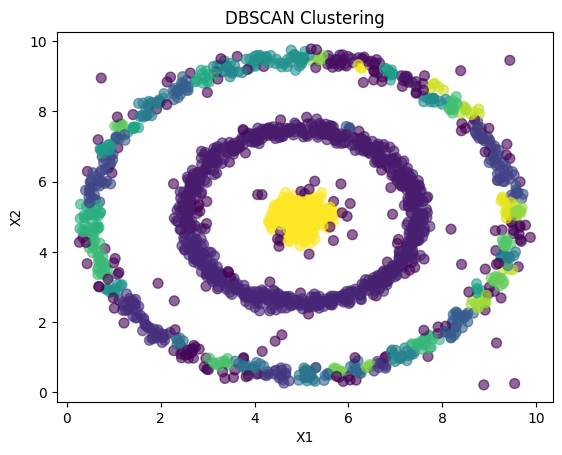

In [47]:
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=50, alpha=0.6)
plt.title('DBSCAN Clustering')
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

In [48]:
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)

In [49]:
sort_distances = np.sort(distances[:, -1])

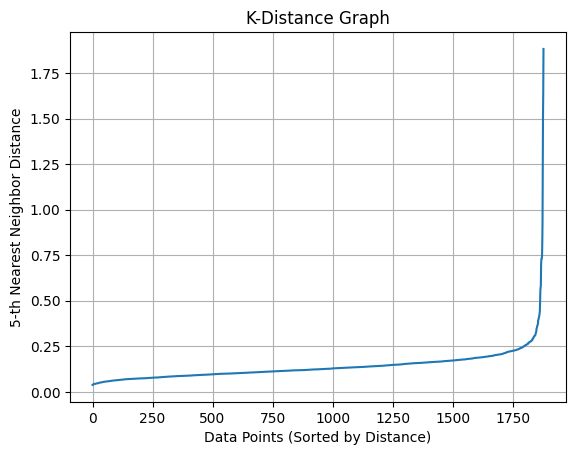

In [50]:
plt.plot(sort_distances)
plt.title("K-Distance Graph")
plt.xlabel("Data Points (Sorted by Distance)")
plt.ylabel(f"{min_samples}-th Nearest Neighbor Distance")
plt.grid(True)

plt.show()

In [62]:
dbscan = DBSCAN(eps = 0.30, min_samples = min_samples)
labels = dbscan.fit_predict(X)

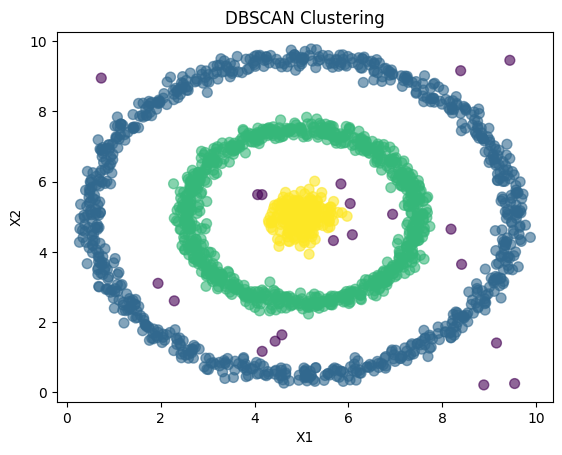

In [63]:
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=50, alpha=0.6)
plt.title('DBSCAN Clustering')
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()